![PIC UPV PERTE Chip Chair Logo](https://www.pic-chair.upv.es/wp-content/uploads/2024/05/logo-upv-horizontal.png)
![PIC UPV PERTE Chip Chair Logo](https://www.pic-chair.upv.es/wp-content/uploads/2024/06/logos-perte-chip-1024x119.png)


# Laboratory 0.3. Ring Resonators

**Duration:** 2 hours | **Tools:** Python, gplugins/Tidy3D mode solver, NumPy, Matplotlib  
**Deliverable:** Fill in the companion `LabBook_030.pptx` with figures, numerical observations and short answers.

We will reuse the SiN/SiO₂ waveguide cross-section from **Lab 0.1**, then use a **simplified analytical circuit model** for an all-pass ring resonator. This is **not** a full electromagnetic simulation of the bent ring or its curved coupling region.

**Learning outcomes**
1. Connect the effective index of a waveguide to ring resonance.
2. Analyze how the ring radius affects the spectral response and FSR.
3. Explain how coupling and round-trip loss affect the depth of transmission dips.

## 0. Imports — run first
Run the cells in order, as in Labs 0.1 and 0.2. Keep dimensions in **µm** inside the Python calculations.

In [91]:
import numpy as np
import matplotlib.pyplot as plt
import gplugins.tidy3d as gt
from scipy.signal import peak_widths, find_peaks

import tidy3d as td
import gplugins as gp


# Units
nm = 1e-3  # 1 nm expressed in µm
# Reference wavelength
lambda0 = 1.55  # µm
# Wavelength sweep for modal analysis
wavelength_modes = np.linspace(1.50, 1.60, 11)  # µm

# Wavelength sweep for ring spectral analysis
lambda_sweep = np.linspace(1.50, 1.60, 4001)  # µm

f = td.C_0 / wavelength_modes

## LO.1. Effective and Group Index Analysis
### 1.0. Reuse the mode solver from Lab 0.1 

The cross-section is the same: **1.2 µm wide, 300 nm high SiN core in SiO₂**. The **fundamental TE-like mode** is used for this introductory example. Inspect the TE fractions if the ordering is different in your solver version.

In [45]:
# Waveguide geometry (same as Lab 0.1)

deep_waveguide = gt.modes.Waveguide(
    core_width=1.2,
    core_thickness=300 * nm,
    slab_thickness=0 * nm,
    core_material='sin',
    clad_material='sio2',
    wavelength=wavelength_modes,
    num_modes=4,
    max_grid_scaling=1.5,
    grid_resolution=20,
    cache_path='.cache/',
    precision='double',
)

# Calculate effective indices and TE fractions
print('Effective indices:', deep_waveguide.n_eff)
print('TE fractions:', deep_waveguide.fraction_te)


2026-11-04 01:20:15.501 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_b5523def2f64287f.npz.


Effective indices: [[1.61576581+9.90075014e-05j 1.53569415+1.79298562e-04j
  1.45730564+1.89681922e-04j 1.43603244+2.25429780e-04j]
 [1.61352052+9.94590080e-05j 1.53396702+1.79020520e-04j
  1.45584098+1.90685722e-04j 1.43570242+2.23961167e-04j]
 [1.61129471+9.99044601e-05j 1.53227246+1.78729004e-04j
  1.4544615 +1.91555371e-04j 1.43537078+2.22512640e-04j]
 [1.60908837+1.00343815e-04j 1.53061007+1.78424502e-04j
  1.45316199+1.92288930e-04j 1.43503751+2.21083867e-04j]
 [1.60690149+1.00777029e-04j 1.52897943+1.78107482e-04j
  1.45193706+1.92887167e-04j 1.43470258+2.19674421e-04j]
 [1.60473406+1.01204059e-04j 1.52738011+1.77778400e-04j
  1.4507813 +1.93353237e-04j 1.43436597+2.18283916e-04j]
 [1.60258605+1.01624862e-04j 1.52581169+1.77437696e-04j
  1.44968936+1.93692261e-04j 1.43402769+2.16911987e-04j]
 [1.60045746+1.02039394e-04j 1.52427377+1.77085797e-04j
  1.44865604+1.93910863e-04j 1.4336877 +2.15557887e-04j]
 [1.59834826+1.02447611e-04j 1.52276591+1.76723112e-04j
  1.44767639+1.940167

### 1.1. Extract the effective index of the fundamental TE mode for different wavelengths

n_eff at 1550 nm = 1.60473


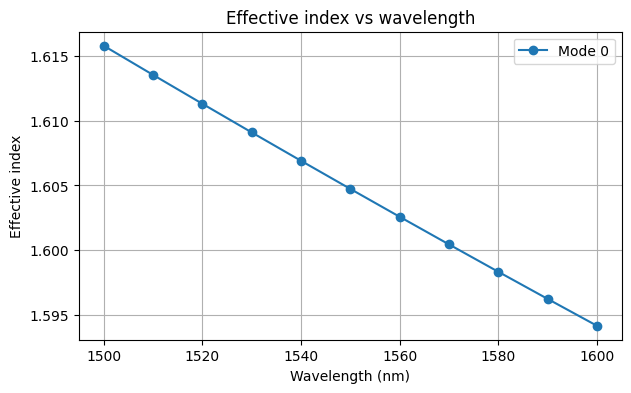

In [33]:
# Select fundamental TE-like mode
te_mode_index = 0

neff = np.real(
        np.asarray(deep_waveguide.n_eff)[:,te_mode_index]
) # vector de índices efectivos para las longitudes de onda de un dels modes

# Plot effective index vs wavelength
plt.figure(figsize=(7, 4))
# plt.scatter(wavelength_modes*1000, neff,edgecolors='k',facecolors='none',label = '__nolegend__')
plt.plot(wavelength_modes*1000, neff, 'o-', label=f'Mode {te_mode_index}')

# Effective index at 1550 nm
idx = np.argmin(np.abs(wavelength_modes - lambda0))
neff_1550 = neff[idx]
print(f'n_eff at 1550 nm = {neff_1550:.5f}')

plt.xlabel('Wavelength (nm)')
plt.ylabel('Effective index')
plt.title('Effective index vs wavelength')
plt.grid(True)
plt.legend(loc='upper right')
plt.show()

n_eff at 1550 nm = 1.60473
n_eff at 1550 nm = 1.52738
n_eff at 1550 nm = 1.45078
n_eff at 1550 nm = 1.43437


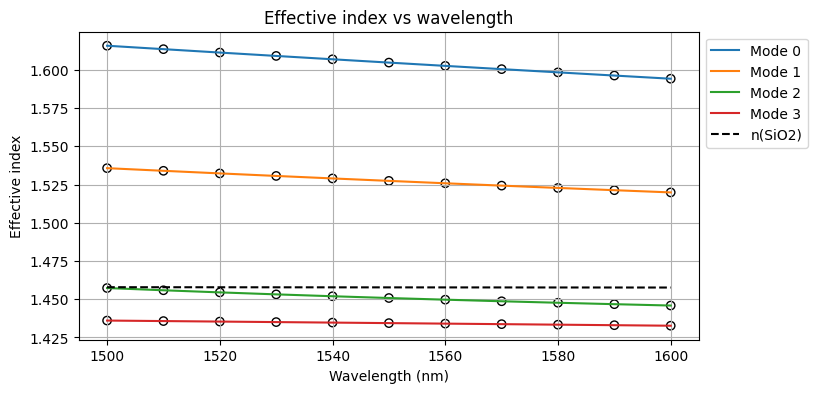

n_g at 1550 nm = 1.93918
n_g at 1550 nm = 1.77288
n_g at 1550 nm = 1.62498
n_g at 1550 nm = 1.48667


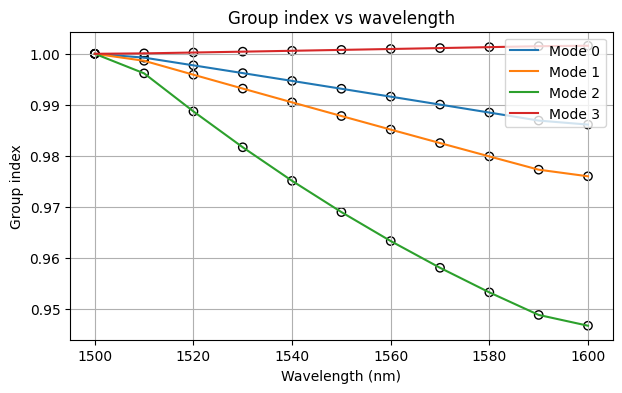

In [ ]:
# # Select fundamental TE-like mode
# te_mode_index = 0
 
# # Plot effective index vs wavelength
# plt.figure(figsize=(8, 4))

# for k in range(deep_waveguide.n_eff.shape[1]):
#     # It's necessary to 'access' each element on the array
#     neff = np.real(
#         np.asarray(deep_waveguide.n_eff)[:,k]
#         ) # vector de índices efectivos para las longitudes de onda de un dels modes
    
#     plt.scatter(wavelength_modes*1000, neff,edgecolors='k',facecolors='none',label = '__nolegend__')
#     plt.plot(wavelength_modes*1000, neff, label=f'Mode {k}')

#     # Effective index at 1550 nm
#     idx = np.argmin(np.abs(wavelength_modes - lambda0))
#     neff_1550 = neff[idx]
#     print(f'n_eff at 1550 nm = {neff_1550:.5f}')



# # plt.plot(wavelength_modes * 1000, neff, 'o-', label=f'Mode {te_mode_index}')

# box_complex = td.material_library["SiO2"]["Horiba"].eps_model(f)
# box_index, box_k = td.Medium.eps_complex_to_nk(box_complex)
# # plt.scatter(wavelength_modes*1000,box_index,edgecolors='k',facecolors='None')
# plt.plot(wavelength_modes*1000, box_index, 'k--', label='n(SiO2)')

# plt.xlabel('Wavelength (nm)')
# plt.ylabel('Effective index')
# plt.title('Effective index vs wavelength')
# plt.grid(True)
# plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
# plt.show()

# # Plot group index vs wavelength
# plt.figure(figsize=(7, 4))
# for k in range(deep_waveguide.n_eff.shape[1]):
#     # It's necessary to 'access' each element on the array
#     neff = np.real(
#         np.asarray(deep_waveguide.n_eff)[:,k]
#         ) # vector de índices efectivos para las longitudes de onda de un dels modes

#     dneff_dlambda = np.gradient(neff, wavelength_modes)
#     # neff ací ve del comando anterior i per tant el index de grup ací és per a un mode en concret
#     # Calculate group index
#     ng = neff - wavelength_modes * dneff_dlambda
    
#     plt.scatter(wavelength_modes*1000, ng/ng[0],edgecolors='k',facecolors='none',label = '__nolegend__')
#     plt.plot(wavelength_modes*1000, ng/ng[0], label=f'Mode {k}')

#     # Group index at 1550 nm
#     ng_1550 = ng[idx]
#     print(f'n_g at 1550 nm = {ng_1550:.5f}')

# # plt.plot(wavelength_modes * 1000, ng, 'o-', label=f'Mode {te_mode_index}')

# plt.xlabel('Wavelength (nm)')
# plt.ylabel('Group index')
# plt.title('Group index vs wavelength')
# plt.grid(True)
# plt.legend(loc='upper right')
# plt.show()

Note: The effective index, n_eff(wvl), is expected to vary smoothly with wavelength. If the plot shows unexpected discontinuities or abrupt changes, the selected mode may not correspond to the fundamental TE-like mode across the entire wavelength range.

In this case, check the effective indices and TE fractions to correctly identify the fundamental TE-like mode, and adjust te_mode_index if necessary.

Important: The effective index must always be obtained from the modal simulation, not replaced by an arbitrary value

### 1.2. Calculate and plot the group index

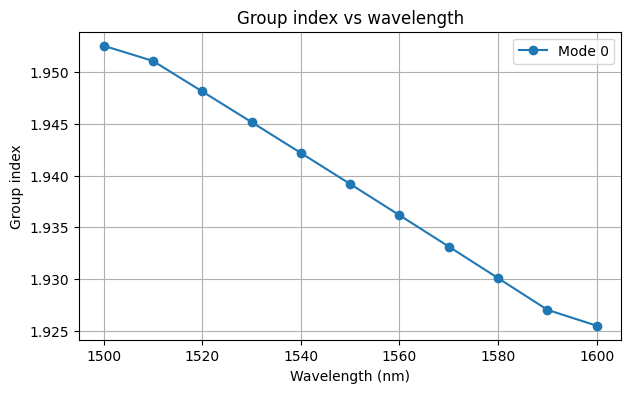

n_g at 1550 nm = 1.93918


In [46]:
te_mode_index = 0
neff = np.real(np.asarray(deep_waveguide.n_eff)[:,te_mode_index])

# Numerical derivative of effective index
dneff_dlambda = np.gradient(neff, wavelength_modes)
# neff ací ve del comando anterior i per tant el index de grup ací és per a un mode en concret
# Calculate group index
ng = neff - wavelength_modes * dneff_dlambda

# Plot group index vs wavelength
plt.figure(figsize=(7, 4))
plt.plot(wavelength_modes * 1000, ng, 'o-', label=f'Mode {te_mode_index}')

plt.xlabel('Wavelength (nm)')
plt.ylabel('Group index')
plt.title('Group index vs wavelength')
plt.grid(True)
plt.legend(loc='upper right')
plt.show()

# Group index at 1550 nm
ng_1550 = ng[idx]

print(f'n_g at 1550 nm = {ng_1550:.5f}')

### LO.2. Ring Resonator Spectral Response 

A ring resonator consists of a closed-loop waveguide coupled to a straight waveguide. At specific wavelengths, light circulating inside the ring satisfies the resonance condition:

$$
m\lambda = n_{\mathrm{eff}}(\lambda)L
$$

where $L = 2\pi R$ is the ring circumference, $R$ is the ring radius, and $m$ is an integer representing the resonance order.

The round-trip phase accumulated by light propagating around the ring is:

$$
\phi(\lambda) = \frac{2\pi n_{\mathrm{eff}}(\lambda)L}{\lambda}
$$

According to the lecture, the through-port power transmission is given by:

$$
T_p(\lambda) = \frac{1+x^2y^2-2xy\cos\phi(\lambda)}{x^2+y^2-2xy\cos\phi(\lambda)}
$$

where:

- $x = 1/a$ is the loss parameter, with $a$ representing the round-trip field-amplitude transmission.
- $y$ is the self-coupling field coefficient between the straight waveguide and the ring.
- $\phi(\lambda)$ is the round-trip phase accumulated inside the ring.

In this exercise, we will use the wavelength-dependent effective index $n_{\mathrm{eff}}(\lambda)$ calculated in LO.1 to simulate the spectral response of an all-pass ring resonator.


### 2.2. Interpolate the Effective Index

In LO.1, we calculated the effective index of the fundamental TE mode at 11 wavelengths between 1500 and 1600 nm.

To accurately represent the narrow resonances of a ring resonator, we need a finer wavelength resolution.

Instead of running additional mode simulations, we will use **linear interpolation** to estimate $n_{\mathrm{eff}}(\lambda)$ over 4001 wavelength points.

This interpolated effective index will be used to calculate the round-trip phase and the spectral response of the ring resonator.

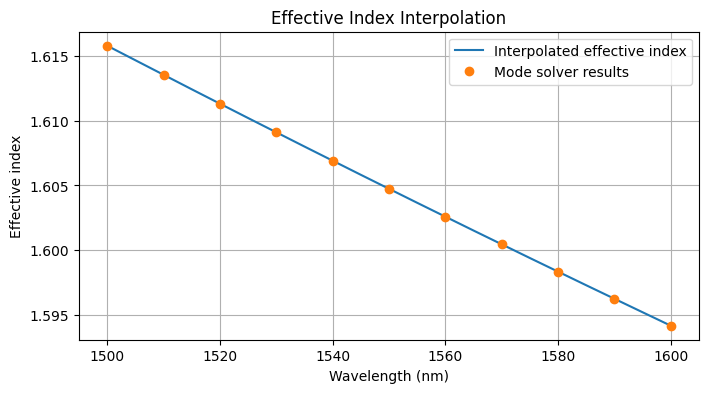

In [96]:
# Interpolate effective index over the wavelength range, we need enough resolution

neff_sweep = np.interp(
    lambda_sweep,
    wavelength_modes,
    neff
)

ng_sweep = np.interp(
    lambda_sweep,
    wavelength_modes,
    ng
)

# Plot original and interpolated effective index
plt.figure(figsize=(8, 4))

plt.plot(lambda_sweep * 1000, neff_sweep, '-',
         label='Interpolated effective index')

plt.plot(wavelength_modes * 1000, neff, 'o',
         label='Mode solver results')

plt.xlabel('Wavelength (nm)')
plt.ylabel('Effective index')
plt.title('Effective Index Interpolation')
plt.legend()
plt.grid(True)
plt.show()

#### QUESTION: Why do we interpolate the effective index instead of running the mode solver at every wavelength point?


### 2.3. Ring Resonator Transmission Spectrum

We will now calculate the through-port transmission spectrum of an all-pass ring resonator using the wavelength-dependent effective index obtained in Section 2.2.

The ring parameters are:

- **Ring radius:** $R = 10$ µm
- **Round-trip field-amplitude transmission:** $a = 0.90$
- **Self-coupling field coefficient:** $y = 0.90$
- **Wavelength range:** 1500–1600 nm

The round-trip phase is calculated as:

$$
\phi(\lambda) = \frac{2\pi n_{\mathrm{eff}}(\lambda) \cdot 2\pi R}{\lambda}
$$

The through-port power transmission is:

$$
T_p(\lambda) = \frac{1+x^2y^2-2xy\cos\phi(\lambda)}{x^2+y^2-2xy\cos\phi(\lambda)}
$$

where $x=1/a$.

We will use these expressions to calculate and plot the transmission spectrum of the resonator.

[1.5126   1.531525 1.551    1.571025 1.59165 ]


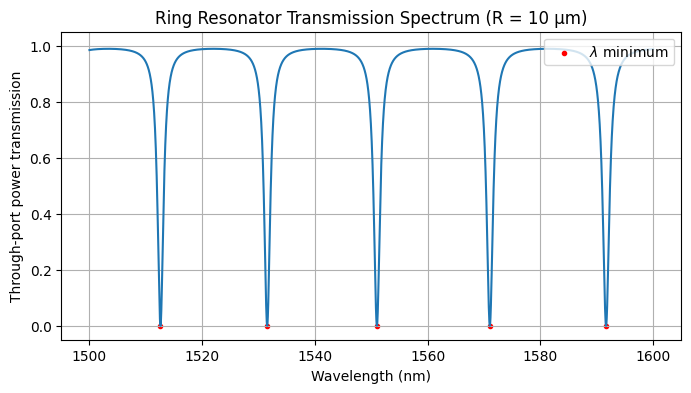

18.925000000000082
19.47500000000013
20.02499999999996
20.624999999999893


In [78]:
# Ring resonator transmission function

def ring_transmission(wavelength_um, radius_um, neff, a=0.90, y=0.90):
    """Calculate the through-port power transmission of an all-pass ring."""

    # Ring circumference (µm)
    L = 2 * np.pi * radius_um

    # Round-trip phase
    phi = 2 * np.pi * neff * L / wavelength_um

    # Loss parameter
    x = 1 / a

    # Power transmission
    numerator = 1 + (x * y)**2 - 2 * x * y * np.cos(phi)
    denominator = x**2 + y**2 - 2 * x * y * np.cos(phi)

    return numerator / denominator


# Ring parameters
radius = 10.0  # µm
a = 0.90       # Round-trip amplitude transmission
y = 0.90       # Self-coupling amplitude coefficient

# Calculate transmission
transmission = ring_transmission(
    lambda_sweep,
    radius,
    neff_sweep,
    a,
    y
)

# Plot transmission spectrum
plt.figure(figsize=(8, 4))

plt.plot(lambda_sweep * 1000, transmission)

plt.xlabel('Wavelength (nm)')
plt.ylabel('Through-port power transmission')
plt.title('Ring Resonator Transmission Spectrum (R = 10 µm)')
plt.ylim(-0.05, 1.05)
plt.grid(True)


max_values, _ = find_peaks(-transmission)
resonance_lambda = lambda_sweep[max_values]
print(resonance_lambda)

plt.scatter(resonance_lambda*1000, transmission[max_values], marker='.', color='red', label=r'$\lambda$ minimum')
plt.legend(loc='upper right')
plt.show()

for k in range(4):
    FSR = resonance_lambda[k+1] - resonance_lambda[k]
    print(FSR*1000)

In [76]:
print(resonance_lambda[0])

1.5126


#### Key Observations

1) Resonance Depth: The through-port transmission drops to nearly zero at the resonant wavelengths due to the critical coupling condition ($a = y = 0.90$).

2) Free Spectral Range (FSR): The spacing between consecutive resonances increases slightly with wavelength (approximately 19–21 nm), consistent with the wavelength dependence of the FSR.

3) Off-Resonance Transmission: Between resonances, the transmission approaches unity, indicating that most of the optical power continues propagating through the straight waveguide rather than being coupled into the ring.

### LO.3. Ring Resonator Design Parameters and Spectral Performance
### 3.1. Influence of Coupling and Losses

The spectral response of a ring resonator depends on two main parameters:

- **Round-trip amplitude transmission ($a$):** represents the optical losses inside the ring.
- **Self-coupling amplitude coefficient ($y$):** determines how light is coupled between the straight waveguide and the ring.

Depending on the relationship between these parameters, three coupling regimes can be identified:

- **Undercoupled:** $y > a$
- **Critically coupled:** $y = a$
- **Overcoupled:** $y < a$

#### Exercise 1 – Influence of the coupling coefficient

Using the `ring_transmission()` function developed in Section 2.3, investigate how the coupling coefficient affects the spectral response.

Keep the ring radius and round-trip losses constant:

- Ring radius: $R = 10$ µm
- Round-trip amplitude transmission: $a = 0.90$

Simulate the following cases:

| Case | Self-coupling coefficient ($y$) | Coupling regime |
|---|---|---|
| A | 0.99 | Undercoupled |
| B | 0.90 | Critically coupled |
| C | 0.70 | Overcoupled |

**Tasks:**

1. Plot the three transmission spectra on the same graph.
2. Compare the resonance depths for the three coupling regimes.
3. Identify which configuration produces the deepest transmission minima.
4. Explain why the through-port transmission approaches zero under critical coupling.

#### Exercise 2 – Influence of optical losses 

Keep the ring radius and coupling coefficient constant:

- Ring radius: $R = 10$ µm
- Self-coupling coefficient: $y = 0.90$

Simulate three different values of round-trip amplitude transmission:

| Case | Round-trip amplitude transmission ($a$) |
|---|---|
| D | 0.99 |
| E | 0.90 |
| F | 0.75 |

**Questions:**

1. How does increasing the propagation loss affect the resonance depth?
2. Which configuration satisfies the critical coupling condition?
3. Can increasing the internal losses produce a deeper resonance? Explain why.

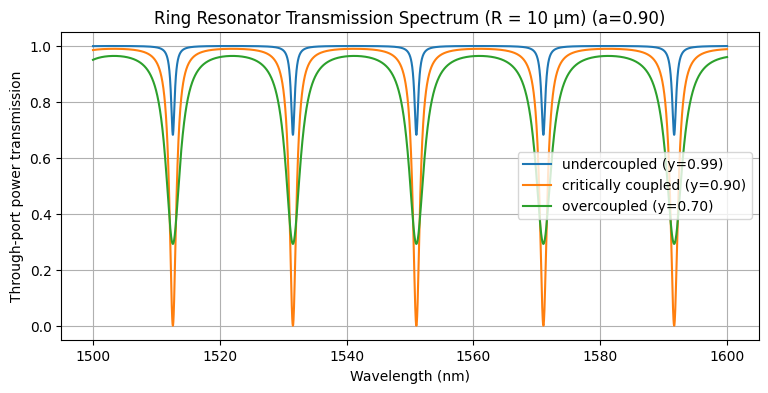

[0.68500991 0.70443022 0.72469711 0.74599735 0.7677399 ]
[1.24372549 1.27910186 1.31582302 1.35437816 1.3927975 ]
[2.65412139 2.72935983 2.80718058 2.88929299 2.95899852]


In [138]:
# Ring parameters
radius = 10.0  # µm
a = 0.90       # Round-trip amplitude transmission
yA = 0.99       # Self-coupling amplitude coefficient (undercoupled)
yB = 0.90       # '' (critically coupled)
yC = 0.70       # '' (overcoupled)
# Calculate transmission
transmission_A = ring_transmission(
    lambda_sweep,
    radius,
    neff_sweep,
    a,
    yA
)
transmission_B = ring_transmission(
    lambda_sweep,
    radius,
    neff_sweep,
    a,
    yB
)
transmission_C = ring_transmission(
    lambda_sweep,
    radius,
    neff_sweep,
    a,
    yC
)

# Plot transmission spectrum
plt.figure(figsize=(9, 4))

plt.plot(lambda_sweep * 1000, transmission_A, label='undercoupled (y=0.99)')
plt.plot(lambda_sweep * 1000, transmission_B, label='critically coupled (y=0.90)')
plt.plot(lambda_sweep * 1000, transmission_C, label='overcoupled (y=0.70)')

plt.xlabel('Wavelength (nm)')
plt.ylabel('Through-port power transmission')
plt.title('Ring Resonator Transmission Spectrum (R = 10 µm) (a=0.90)')
plt.ylim(-0.05, 1.05)
plt.grid(True)
plt.legend(loc='center right')
plt.show()

# encontrar resonancias
peaks_A, _ = find_peaks(-transmission_A)
peaks_B, _ = find_peaks(-transmission_B)
peaks_C, _ = find_peaks(-transmission_C)

# linewidth FWHM
widths_A, height_A, left_A, right_A = peak_widths(-transmission_A, peaks_A, rel_height=0.5)
widths_B, height_B, left_B, right_B = peak_widths(-transmission_B, peaks_B, rel_height=0.5)
widths_C, height_C, left_C, right_C = peak_widths(-transmission_C, peaks_C, rel_height=0.5)

# convertir de muestras a unidades físicas
dx = np.mean(np.diff(lambda_sweep))
linewidth_A= widths_A * dx
linewidth_B= widths_B * dx
linewidth_C= widths_C * dx

print(linewidth_A*1000)
print(linewidth_B*1000)
print(linewidth_C*1000)


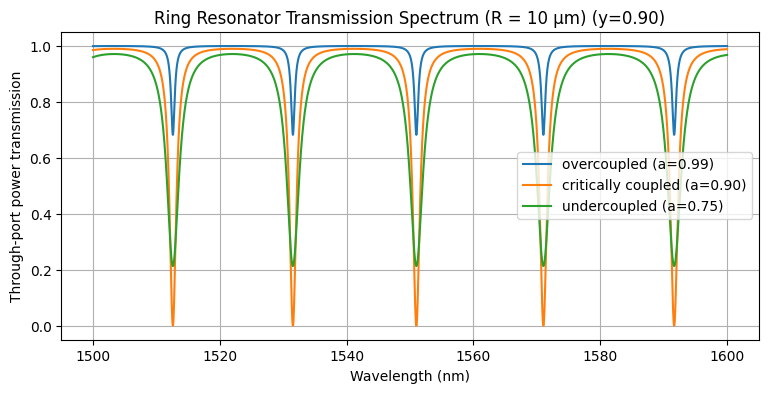

[0.68500991 0.70443022 0.72469711 0.74599735 0.7677399 ]
[1.24372549 1.27910186 1.31582302 1.35437816 1.3927975 ]
[2.27891733 2.34344542 2.41049177 2.48098784 2.54438521]


In [137]:
# Ring parameters
radius = 10.0  # µm
y = 0.90        # Self-coupling amplitude coefficient
aD = 0.99       # Round-trip amplitude transmission (overcoupled)
aE = 0.90       # '' (critically coupled)
aF = 0.75       # '' (undercoupled)
# Calculate transmission
transmission_D = ring_transmission(
    lambda_sweep,
    radius,
    neff_sweep,
    aD,
    y
)
transmission_E = ring_transmission(
    lambda_sweep,
    radius,
    neff_sweep,
    aE,
    y
)
transmission_F = ring_transmission(
    lambda_sweep,
    radius,
    neff_sweep,
    aF,
    y
)
transmission_G = ring_transmission(
    lambda_sweep,
    radius,
    neff_sweep,
    0.999,
    y
)

# Plot transmission spectrum
plt.figure(figsize=(9, 4))

plt.plot(lambda_sweep * 1000, transmission_D, label='overcoupled (a=0.99)')
plt.plot(lambda_sweep * 1000, transmission_E, label='critically coupled (a=0.90)')
plt.plot(lambda_sweep * 1000, transmission_F, label='undercoupled (a=0.75)')


plt.xlabel('Wavelength (nm)')
plt.ylabel('Through-port power transmission')
plt.title('Ring Resonator Transmission Spectrum (R = 10 µm) (y=0.90)')
plt.ylim(-0.05, 1.05)
plt.grid(True)
plt.legend(loc='center right')
plt.show()

# encontrar resonancias
peaks_D, _ = find_peaks(-transmission_D)
peaks_E, _ = find_peaks(-transmission_E)
peaks_F, _ = find_peaks(-transmission_F)

# linewidth FWHM
widths_D, height_D, left_D, right_D = peak_widths(-transmission_D, peaks_D, rel_height=0.5)
widths_E, height_E, left_E, right_E = peak_widths(-transmission_E, peaks_E, rel_height=0.5)
widths_F, height_F, left_F, right_F = peak_widths(-transmission_F, peaks_F, rel_height=0.5)

# convertir de muestras a unidades físicas
dx = np.mean(np.diff(lambda_sweep))
linewidth_D= widths_D * dx
linewidth_E= widths_E * dx
linewidth_F= widths_F * dx

print(linewidth_D*1000)
print(linewidth_E*1000)
print(linewidth_F*1000)


In [ ]:
[0.68500991 0.70443022 0.72469711 0.74599735 0.7677399 ]
[1.24372549 1.27910186 1.31582302 1.35437816 1.3927975 ]
[2.65412139 2.72935983 2.80718058 2.88929299 2.95899852]

### 3.2. Influence of Ring Radius on the Free Spectral Range (25 min)

The **Free Spectral Range (FSR)** is the spectral separation between two consecutive resonances of a ring resonator.

The FSR expressed in wavelength can be approximated as:

$$
FSR_\lambda \approx \frac{\lambda^2}{n_g(\lambda)L}
$$

where:

- $\lambda$ is the resonance wavelength.
- $n_g$ is the group index calculated in LO.1.
- $L = 2\pi R$ is the ring circumference.

This expression shows that the FSR depends on both the group index and the physical length of the resonator.

#### Exercise 3 – Influence of Ring Radius

Using the `ring_transmission()` function developed in Section 2.3, investigate how the ring radius affects the spectral response.

Keep the coupling and loss parameters constant:

- Round-trip amplitude transmission: $a = 0.90$
- Self-coupling coefficient: $y = 0.90$
- Wavelength range: 1500–1600 nm

Simulate the following ring radii:

| Case | Ring radius ($R$) |
|---|---|
| A | 5 µm |
| B | 10 µm |
| C | 20 µm |

**Tasks:**

1. Plot the transmission spectra of the three resonators and compare their resonance spacing.
2. Identify two consecutive resonances near 1550 nm and calculate the FSR for each ring radius.
3. Using the group index obtained in LO.1, calculate the theoretical FSR at 1550 nm for each radius.
4. Complete the following table and compare the numerical and theoretical results.

| Radius (µm) | Simulated FSR (nm) | Theoretical FSR (nm) |
|-----|----|----|
| 5 | | |
| 10 | | |
| 20 | | |

**Questions:**

1. How does the FSR change when the ring radius increases?
2. Explain physically why the FSR depends on the ring circumference.
3. Why is the FSR not exactly constant across the wavelength range?

**Note:** In this exercise, the effective and group indices are assumed to be independent of the ring radius. Bending-induced changes in the guided mode and propagation losses are neglected.

[1.531525 1.571025]
[1.5126   1.531525 1.551    1.571025 1.59165 ]
[1.503325 1.5126   1.522    1.531525 1.5412   1.551    1.56095  1.571025
 1.581275 1.59165 ]


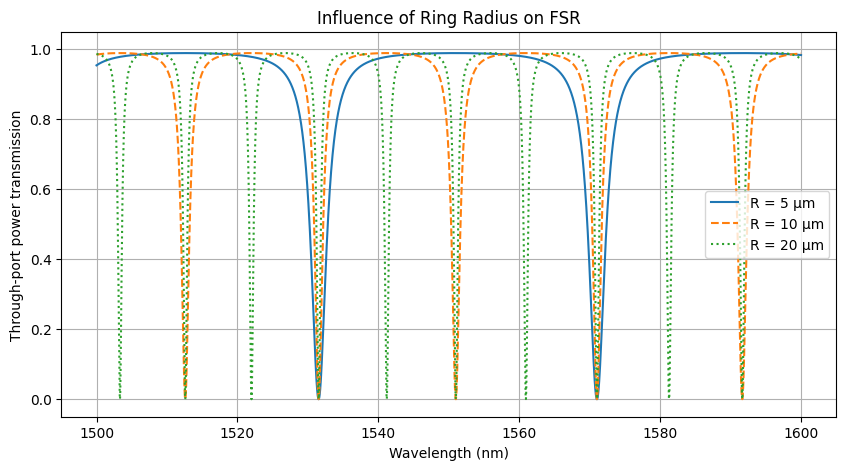

FSR a 1.550 um = 39.43621923337349 nm
FSR a 1.550 um = 19.718109616686746 nm
FSR a 1.550 um = 9.859054808343373 nm
39.49999999999987 19.762500000000017 9.80833333333332


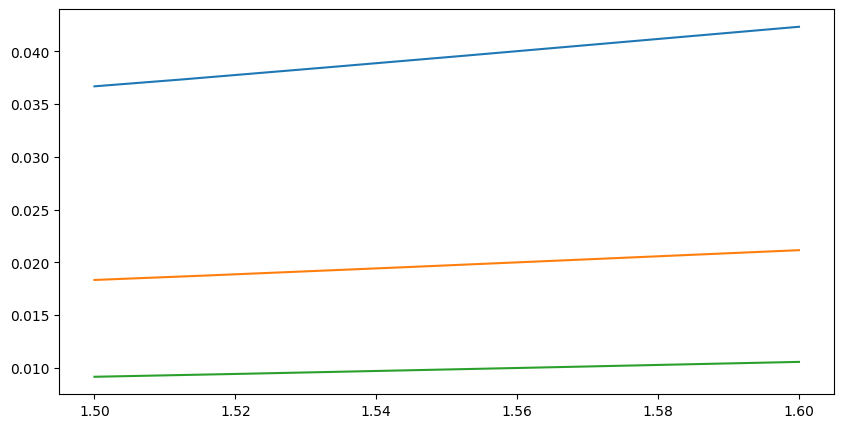

In [101]:

# Exercise 3 - Influence of ring radius on FSR

# Fixed parameters
a = 0.90
y = 0.90

# Ring radii (µm)
radii = [5, 10, 20]
style = ['-', '--', ':']

# Plot transmission spectra
plt.figure(figsize=(10, 5))

for k in range(3):
    T = ring_transmission(
        lambda_sweep,
        radii[k],
        neff_sweep,
        a,
        y
    )

    plt.plot(
        lambda_sweep * 1000,
        T, linestyle=style[k],
        label=f'R = {radii[k]} µm'
    )

    max_values, _ = find_peaks(-T)
    resonance_lambda = lambda_sweep[max_values]
    print(resonance_lambda)

plt.xlabel('Wavelength (nm)')
plt.ylabel('Through-port power transmission')
plt.title('Influence of Ring Radius on FSR')
plt.ylim(-0.05, 1.05)
plt.legend()
plt.grid(True)
plt.show()

# Buscamos máximos spectra
plt.figure(figsize=(10, 5))
for R in radii:
    T = ring_transmission(
            lambda_sweep,
            R,
            neff_sweep,
            a,
            y
        )
    theo_fsr = lambda_sweep**2/(2*np.pi*R*ng_sweep)
    idx = np.argmin(np.abs(lambda_sweep - 1.550))
    fsr_1550 = theo_fsr[idx]

    print(f"FSR a {lambda_sweep[idx]:.3f} um = {fsr_1550*1000} nm")
    plt.plot(lambda_sweep, theo_fsr)

FSR_5 = -(1.531525 - 1.571025)*1000
FSR_10 = -((1.5126-1.531525) + (1.531525-1.551) + (1.551-1.571025) + (1.571025-1.59165))*1000/4
FSR_20 = -((1.503325-1.5126) + (1.5126-1.522) + (1.522-1.531525) + (1.531525-1.5412) + (1.5412-1.551) + (1.551-1.56095) + (1.56095-1.571025) + 
(1.571025-1.581275) + (1.581275-1.5916))*1000/9

print(FSR_5, FSR_10, FSR_20)

# theoretical FSR = lambda**2/n_g(lambda)L, tal que L=2Pi R

In [36]:
# Theoretical FSR at 1550 nm

for R in radii:
    L = 2 * np.pi * R

    FSR_um = lambda0**2 / (ng_1550 * L)
    FSR_nm = FSR_um * 1000

    print(f'R = {R:2d} µm -> Theoretical FSR = {FSR_nm:.2f} nm')

R =  5 µm -> Theoretical FSR = 39.44 nm
R = 10 µm -> Theoretical FSR = 19.72 nm
R = 20 µm -> Theoretical FSR = 9.86 nm


In [103]:
FSR_5 = -(1.531525 - 1.571025)*1000
FSR_10 = -((1.531525-1.551) + (1.551-1.571025))*1000/2
FSR_20 = -((1.5412-1.551) + (1.551-1.56095))*1000/2

print(FSR_5, FSR_10, FSR_20)

39.49999999999987 19.749999999999936 9.875000000000078



### 3.3. Resonance Linewidth and Applications 

The spectral performance of a ring resonator is not only determined by its Free Spectral Range (FSR), but also by the **width of its resonances**.

The **Full Width at Half Maximum (FWHM)** describes the spectral width of a resonance. For a transmission dip, it is measured at half of the resonance depth, relative to the off-resonance transmission level.

Two additional parameters are commonly used to characterize optical resonators:

**Finesse:**

$$
\mathcal{F} = \frac{FSR}{FWHM}
$$

**Loaded Quality Factor (Q-factor):**

$$
Q = \frac{\lambda_R}{FWHM}
$$

where $\lambda_R$ is the resonance wavelength and the FWHM is expressed in the same wavelength units.

A narrower resonance generally corresponds to higher finesse and a higher loaded Q-factor, for a fixed resonance wavelength and FSR.

#### Exercise 4 – Influence of Coupling and Losses on Resonance Linewidth

Consider two critically coupled ring resonators with the same radius but different round-trip losses and coupling coefficients.

| Parameter | Ring A | Ring B |
|---|---|---|
| Radius ($R$) | 10 µm | 10 µm |
| Round-trip amplitude transmission ($a$) | 0.90 | 0.99 |
| Self-coupling coefficient ($y$) | 0.90 | 0.99 |
| Coupling regime | Critical | Critical |

Using `ring_transmission()`, simulate both resonators and compare their transmission spectra.

**Student tasks:**

1. Plot both transmission spectra over the wavelength range of 1500–1600 nm.
2. Zoom in on a resonance near 1550 nm and compare the resonance linewidths.
3. Graphically estimate the FWHM of each resonance by identifying the two wavelengths at half of the resonance depth (approximately T = 0.5). No additional simulations are required.
4. Calculate the finesse and loaded Q-factor for both resonators.

Complete the following table:

| Parameter | Ring A | Ring B |
|---|---|---|
| Resonance wavelength (nm) | | |
| FSR (nm) | | |
| Estimated FWHM (nm) | | |
| Finesse | | |
| Loaded Q-factor | | |

#### Discussion – Applications

Ring resonators are widely used in integrated photonics for optical filtering, sensing and wavelength-selective devices.

**Questions:**

1. Which resonator has the narrower resonance and higher Q-factor?
2. Why does reducing the round-trip loss, while maintaining critical coupling, produce a narrower resonance?
3. Which resonator would be more suitable for detecting small resonance wavelength shifts in an optical sensor? Explain your choice.
4. Is a narrower resonance always advantageous for wavelength-division multiplexing (WDM) filtering? Consider the trade-off between spectral selectivity and operational bandwidth.


[1512.6   1531.525 1551.    1571.025 1591.65 ]
[1.24372549 1.27910186 1.31582302 1.35437816 1.3927975 ]
[1512.6   1531.525 1551.    1571.025 1591.65 ]
[0.12205779 0.12579809 0.12881844 0.1330208  0.13642401]


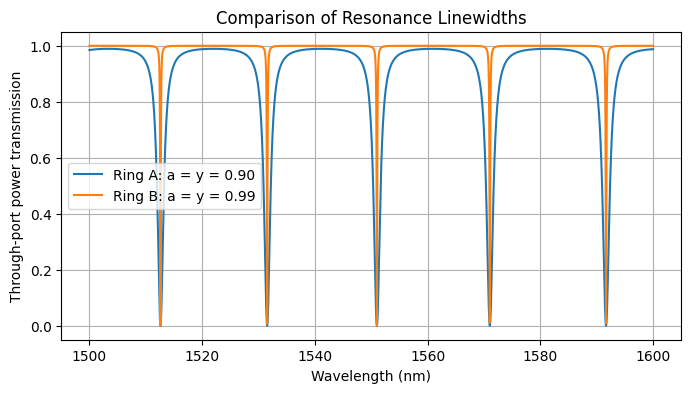

FSR_theo (1550 nm) = 19.718110 nm
19.747499999999945
finesse: ringA = 15.007717384608762, ringB = 153.29715806925054
quality factor: ringA = 1178.729948779757, ringB = 12040.202160547322
0.1288184350493908
1.3158230191789253


In [142]:

# Exercise 4 - Resonance linewidth comparison

radius = 10.0  # µm

# Ring A: higher losses
a_A = 0.90
y_A = 0.90

# Ring B: lower losses
a_B = 0.99
y_B = 0.99

# Calculate transmission spectra
T_A = ring_transmission(
    lambda_sweep, radius, neff_sweep, a_A, y_A
)

# encontrar resonancias
peaks_A, _ = find_peaks(-T_A)
# linewidth FWHM
widths_A, height_A, left_A, right_A = peak_widths(-T_A, peaks_A, rel_height=0.5)
# convertir de muestras a unidades físicas
dx = np.mean(np.diff(lambda_sweep))
linewidth_A= widths_A * dx
print(lambda_sweep[peaks_A]*1000)
print(linewidth_A*1000)

T_B = ring_transmission(
    lambda_sweep, radius, neff_sweep, a_B, y_B
)

peaks_B, _ = find_peaks(-T_B)
widths_B, height_B, left_B, right_B = peak_widths(-T_B, peaks_B, rel_height=0.5)
linewidth_B= widths_B * dx
print(lambda_sweep[peaks_B]*1000)
print(linewidth_B*1000)

plt.figure(figsize=(8, 4))
plt.plot(lambda_sweep * 1000, T_A,
         label='Ring A: a = y = 0.90')

plt.plot(lambda_sweep * 1000, T_B,
         label='Ring B: a = y = 0.99')

plt.xlabel('Wavelength (nm)')
plt.ylabel('Through-port power transmission')
plt.title('Comparison of Resonance Linewidths')
plt.ylim(-0.05, 1.05)
plt.legend()
plt.grid(True)
plt.show()


FSR_theo = (1.550**2/ (ng_1550 * 2 * np.pi * 10))*1000
print(f'FSR_theo (1550 nm) = {FSR_theo:2f} nm')

FSR_exp = (1551-1531.525)/2 + (1571.02-1551)/2
print(FSR_exp)

#Finesse = FSR/FWHM
F_A = FSR_exp/(linewidth_A[2]*1000)
F_B = FSR_exp/(linewidth_B[2]*1000)

#Q = lambda_R/FWHM
Q_A = 1551/(linewidth_A[2]*1000)
Q_B = 1551/(linewidth_B[2]*1000)

print(f'finesse: ringA = {F_A}, ringB = {F_B}')
print(f'quality factor: ringA = {Q_A}, ringB = {Q_B}')
print(linewidth_B[2]*1000)
print(linewidth_A[2]*1000)

In [127]:
#A
print(1551-0.12881844/2, 1551+0.12881844/2)

print(1551-1.31582302/2, 1551+1.31582302/2)

1550.93559078 1551.06440922
1550.34208849 1551.65791151


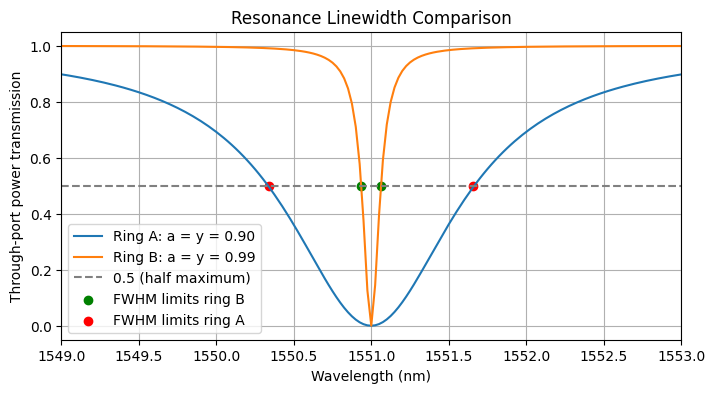

In [153]:
# Zoom around a resonance near 1550 nm

plt.figure(figsize=(8, 4))

plt.plot(lambda_sweep * 1000, T_A,
         label='Ring A: a = y = 0.90')

plt.plot(lambda_sweep * 1000, T_B,
         label='Ring B: a = y = 0.99')

# Zoom around the resonance
plt.xlim(1549, 1553)
plt.ylim(-0.05, 1.05)

plt.xlabel('Wavelength (nm)')
plt.ylabel('Through-port power transmission')
plt.title('Resonance Linewidth Comparison')



plt.hlines(y=0.5, xmin=1549, xmax=1553, linestyles='--', color='gray', label='0.5 (half maximum)')

plt.scatter(([1550.93559078, 1551.06440922]), ([0.5, 0.5]), color='green', marker='o', label='FWHM limits ring B')
plt.scatter(([1550.34208849, 1551.65791151]), ([0.5, 0.5]), color='red', marker='o', label='FWHM limits ring A')


plt.legend()
plt.grid(True)
plt.show()